In [ ]:
# to fetch live data we can fetch in two ways 1)API KEY 2) LIBRARIES
#concept: moving average:rather than taking result based on daily basis so we decide to take 3days/week wise/mothly wise average and check the performances

In [1]:
# here we are using yfinance libraries
# pip install yfinance

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------- ----- 1.8/2.1 MB 10.2 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 8.6 MB/s  0:00:00
   ---------------------------------------- 0.0/4.1 MB ? eta -:--:--
   -------------------- ------------------- 2.1/4.1 MB 9.7 MB/s eta 0:00:01
   -------------------------------------- - 3.9/4.1 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 4.1/4.1 MB 8.7 MB/s  0:00:00

   ---------------------------------------- 0/6 [peewee]
   ---------------------------------------- 0/6 [peewee]
   ---------------------------------------- 0/6 [peewee]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
   ------ --------------------------------- 1/6 [lxml]
  Attempting uninstall: cffi
   ------ -

In [2]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

=========== Complete Stock Analyzer =============


Enter the stock symbol (or 'Quit' to exit): Reliance.NS



 --------------------------------
 Company : Reliance Industries Limited
 Current Price : 1324.4 INR
 Change: +0.40 (+0.03%)

 --------------------------------


Enter the start date (yyyy-mm-dd): 2022-06-13
Enter the end date (yyyy-mm-dd): 2026-09-09


[*********************100%***********************]  1 of 1 completed


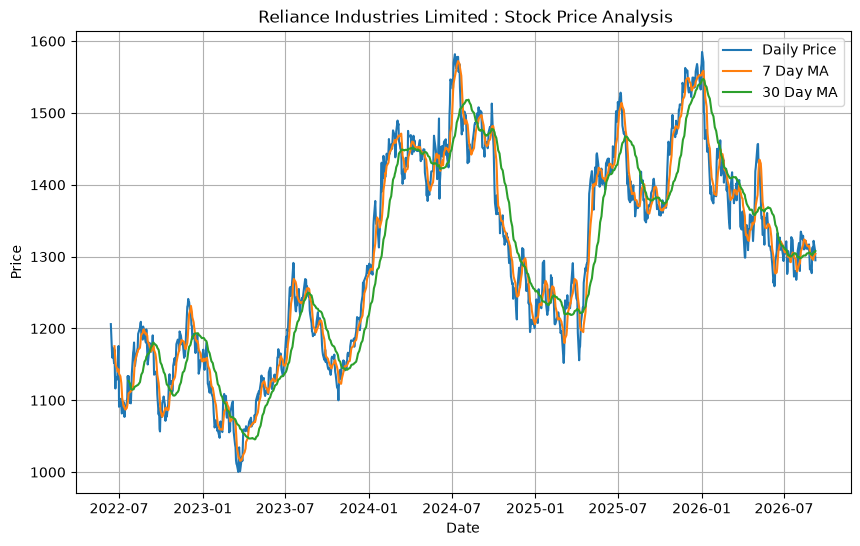

Enter the stock symbol (or 'Quit' to exit): quit


Exiting Program. Thanks for using.


In [4]:
print("=========== Complete Stock Analyzer =============")  # every stock market have there symbol
while True:
    symbol = input("Enter the stock symbol (or 'Quit' to exit):").upper()
    
    if symbol == "QUIT":
        print("Exiting Program. Thanks for using.")
        break
    # try it if server down dont show error in our code show the msg 
    try:
        stock = yf.Ticker(symbol) #ticker is like search
        info = stock.info
        
         # here we need to show company full name, current price,previous day price to show the diff b/w today day price and prevoius close price,currency)
        name = info.get("longName","N/A")
        price = info.get("currentPrice")
        prev_close = info.get("previousClose")
        currency = info.get("currency","USD")  #if currency not there then show usd one

        print("\n --------------------------------")
        print(f" Company : {name}")
        print(f" Current Price : {price} {currency}")

        #calculation prvious price-current price give diff how much increment /growth wasthere 
        if price and prev_close:
            change = price - prev_close
            percent = (change/prev_close)*100

            print(f" Change: {change:+.2f} ({percent:+.2f}%)")

        print("\n --------------------------------")

        # from which date to which date we need to see the performance so we need start date and end date

        start_date = input("Enter the start date (yyyy-mm-dd):")
        end_date = input("Enter the end date (yyyy-mm-dd):")

        # from yaho  finance the data is downloaded at stored in the df and interval for many days you want 1d,7d,...)
        df = yf.download(symbol, start = start_date, end = end_date, interval="1d")
        # 7 day moving average (create new column based on close column)
        df["7_day_MA"] = df["Close"].rolling(window=7).mean()
        #30 day moving average
        df["30_day_MA"] = df["Close"].rolling(window=30).mean()

        
        #Plot the graph
        plt.figure(figsize=(10,6))
        plt.plot(df["Close"],label = "Daily Price")
        plt.plot(df["7_day_MA"], label= "7 Day MA")
        plt.plot(df["30_day_MA"], label = "30 Day MA")
        plt.title(f" {name} : Stock Price Analysis")
        plt.xlabel("Date")
        plt.ylabel("Price")
        plt.legend()
        plt.grid(True)
        plt.show()
        

    except Exception as e:
        print("Invalid Symbol or Network Error")
